# Практическая работа №3. Свёрточные нейронные сети

**Работу выполнил (а):**

Басиони Абдельсалам Али Абдельсалам, 465144

# Классификация цветов с помощью свёрточных нейронных сетей.


В работе необходимо познакомится с различными архитектурами сверхточных нейронных сетей и их обучением на GPU (англ. graphics processing, графический процессор) на языке программирования Python 3 и фреймворка Torch (PyTorch).  Для этого предлагается использовать ресурсы Google Colab - Colaboratory, для выполнения вычислений на GPU. После с ознакомления, выполнить практическое задане в конце данной тетради (notebook).

Рассмотрим [Датасет](https://www.kaggle.com/alxmamaev/flowers-recognition ) содержащий 4242 изображения цветов размеченных по 5 видам (тюльпан, ромашка, подсолнух, роза, одуванчик). Данный набор данных можно скачать по [ссылке](https://www.kaggle.com/alxmamaev/flowers-recognition ) с сайте kaggle.

Загрузите папку с картинками на гугл диск, чтобы не загружать ее каждый раз заново при перезапуске колаба. Структура файлов (можно посмотреть в меню слева) может быть такой: "/content/drive/My Drive/data/flowers".

Обязательно подключите аппаратный ускоритель (GPU) к среде выполнения. В меню сверху: Среда выполнения -> Сменить среду выполнения

A CNN is a neural network specifically designed for image processing.

It automatically extracts features from images:
- Early layers detect edges.
- Deeper layers detect shapes and textures.
- Later layers recognize more complex features.
- The final classifier predicts the image class.

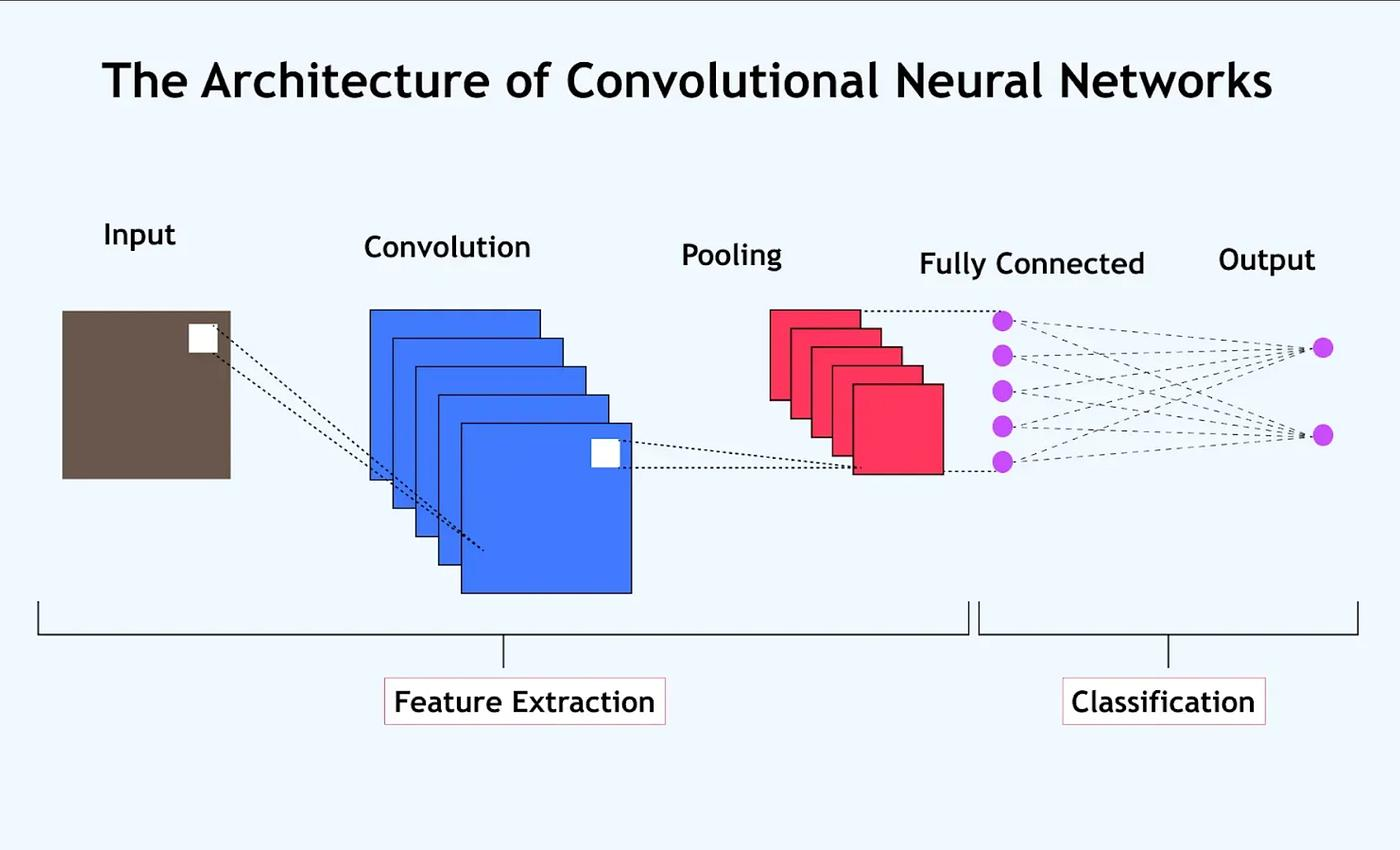

Первым делом разберите более детально код выполнив код ниже.

# Подготовка

Загружаем библиотеки. Фиксируем random.seed для воспроизводимости

In [6]:
import numpy as np
import os
import torch
import torchvision
from torchvision.datasets.utils import download_url
from torch.utils.data import random_split
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torchvision.transforms import ToTensor
from torch.utils.data.dataloader import DataLoader
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import random
from tqdm import tqdm
import matplotlib.pyplot as plt

random.seed(0)
torch.manual_seed(0)
import time

Выбираем на чем будем делать вычисления - CPU или GPU (cuda)

In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


Блок для соединения с Google Colab

In [8]:
# In Google Colab the data is on Google Drive; when run locally it is in the folder data/flowers
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    DATA_DIR = '/content/drive/My Drive/data/flowers'
except ImportError:
    DATA_DIR = 'data/flowers'
print(DATA_DIR)

Mounted at /content/drive
/content/drive/My Drive/data/flowers


In [9]:
import os

# التأكد إن المسار موجود
print('المسار موجود؟', os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    # عرض المجلدات اللي جوه
    classes = os.listdir(DATA_DIR)
    print('المجلدات اللي جوه:', classes)

    # عد الصور في كل مجلد
    for cls in classes:
        class_path = os.path.join(DATA_DIR, cls)
        if os.path.isdir(class_path):
            num_images = len(os.listdir(class_path))
            print(f'  - {cls}: {num_images} صورة')
else:
    print('⚠️ المسار غلط أو المجلد مش موجود!')

المسار موجود؟ True
المجلدات اللي جوه: ['sunflower', 'dandelion', 'tulip', 'rose', 'daisy']
  - sunflower: 733 صورة
  - dandelion: 1052 صورة
  - tulip: 994 صورة
  - rose: 784 صورة
  - daisy: 764 صورة


In [ ]:
prepare_imgs = torchvision.transforms.Compose(
    [
        torchvision.transforms.Resize((224, 224)), #приводим картинки к одному размеру pixels
        torchvision.transforms.ToTensor(), # упаковывем их в тензор for pytorch
        torchvision.transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225] # нормализуем картинки по каналам stdv 1 and mean 0
        ),
    ]
)
# задаем датасет. Лейблы - имена папок:
dataset = ImageFolder(DATA_DIR, transform=prepare_imgs)

In [11]:
dataset.imgs[2]

('/content/drive/My Drive/data/flowers/daisy/10172379554_b296050f82_n.jpg', 0)

In [12]:
# Classes and number of images in each class
print('Классы:', dataset.classes)
print('Всего изображений:', len(dataset))
print(pd.Series([dataset.classes[label] for _, label in dataset.imgs]).value_counts())

Классы: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Всего изображений: 4327
dandelion    1052
tulip         994
rose          784
daisy         764
sunflower     733
Name: count, dtype: int64


In [13]:
class ValueMeter(object):
  """
  Вспомогательный класс, чтобы отслеживать loss и метрику
  """
  def __init__(self):
      self.sum = 0
      self.total = 0

  def add(self, value, n):
      self.sum += value*n
      self.total += n

  def value(self):
      return self.sum/self.total

def log(mode, epoch, loss_meter, accuracy_meter, best_perf=None):
  """
  Вспомогательная функция, чтобы
  """
  print(
      f"[{mode}] Epoch: {epoch:0.2f}. "
      f"Loss: {loss_meter.value():.2f}. "
      f"Accuracy: {100*accuracy_meter.value():.2f}% ", end="\n")

  if best_perf:
      print(f"[best: {best_perf:0.2f}]%", end="")


# Сверточная нейросеть с нуля

## Вручную прописываем слои
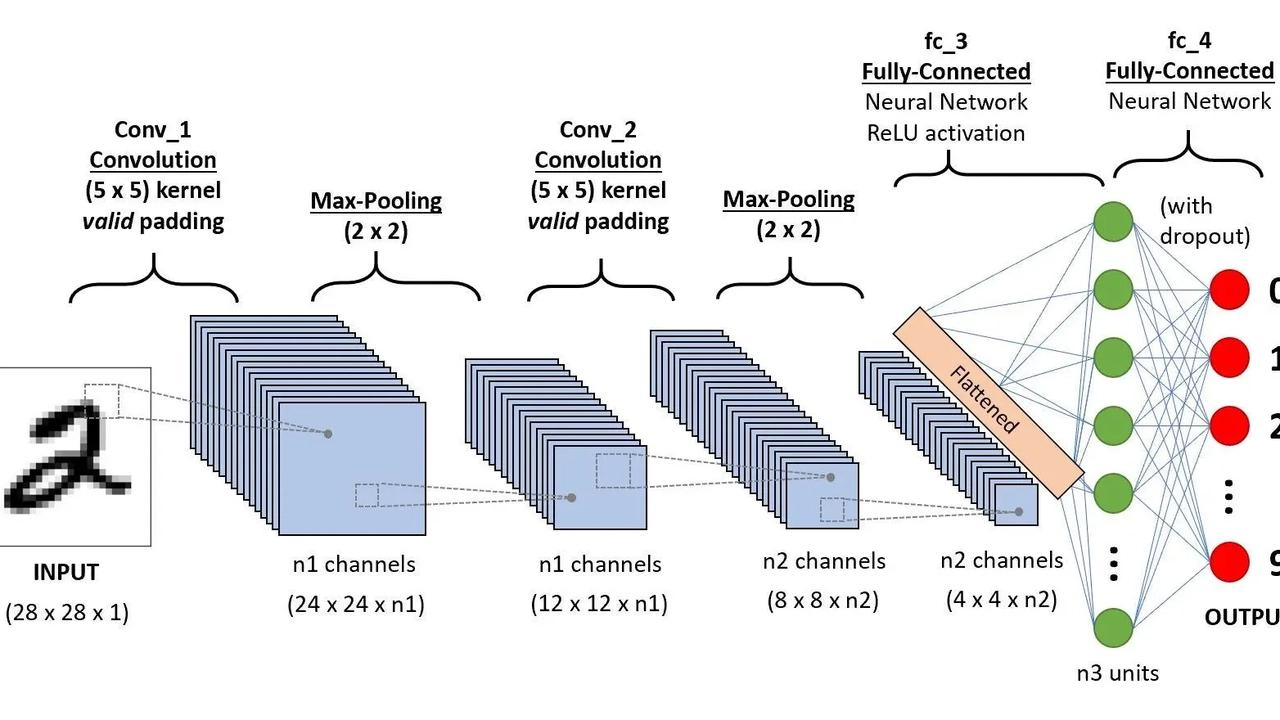

In [ ]:
model = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1), #out channel = no of filters
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1), #convolution layer uses filters and kernel to extract feature like edges shapes and texture
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # output: 64 x 112 x 112
# Max Pooling selects the maximum value from each 2×2 region, reducing the spatial dimensions of the feature maps.
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # output: 128 x 56 x 56

            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # output: 256 x 28 x 28

            nn.Flatten(), # Converts multidimensional feature maps into a one-dimensional vector.
            nn.Linear(256*28*28, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 5)) #Fully connected layers use extracted features to perform classification. The final layer produces five output scores, one for each flower class.
model.to(device) # отправляем модель на девайс (GPU)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU()
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU()
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU()
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU()
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Flatten(start_dim=1, end_dim=-1)
  (16): Linear(in_features=200704, out_features=1024, bias=True)
  (17): ReLU()
  (18): Linear(in_features=1024, out_features=512, bias=True)
  (19): ReLU()
  (20): Lin

*Примечание:* в исходном шаблоне в комментариях были размеры 64 × 16 × 16, 128 × 8 × 8, 256 × 4 × 4 — они верны для картинок 32 × 32. У нас картинки 224 × 224, поэтому после трёх MaxPool размер 224 → 112 → 56 → 28, и первый полносвязный слой принимает 256·28·28 входов. Комментарии исправлены.

ReLU introduces non-linearity by replacing negative values with zero.
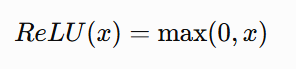

In [15]:
# Number of trainable parameters (weights and biases)
def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print(f'Параметров в базовой сети: {count_params(model):,}')
print(f'Из них в первом полносвязном слое: {256*28*28*1024 + 1024:,}')

Параметров в базовой сети: 207,175,365
Из них в первом полносвязном слое: 205,521,920


Задаем гиперпараметры для обучения:

# Задаем параметры и функцию для обучения. Разбиваем датасет на train/validation

In [ ]:
batch_size = 32 #Batch Size is the number of training images processed before one optimizer update.
lr = 0.001  #: Learning Rate controls how much the model's weights change during each optimization step.
optimizer = torch.optim.Adam(params = model.parameters(), lr=lr)  # lr is now passed to the optimizer
#Adam is an optimization algorithm that updates model parameters to minimize the loss function.

Разбиваем датасет на train и validation

Задаем dataloader'ы - объекты для итеративной загрузки данных и лейблов для обучения и валидации

In [ ]:
train_set, val_set = torch.utils.data.random_split(dataset, [len(dataset)-1000, 1000]) #1000 validation
print('Размер обучающего и валидационного датасета: ', len(train_set), len(val_set))
num_workers = 2 if device == 'cuda' else 0   # on CPU extra loader processes only use up memory
loaders = {'training': DataLoader(train_set, batch_size, pin_memory=True,num_workers=num_workers, shuffle=True),
           'validation':DataLoader(val_set, batch_size, pin_memory=True,num_workers=num_workers, shuffle=False)}

Размер обучающего и валидационного датасета:  3327 1000


Функция для подсчета Accuracy

In [18]:
def accuracy(outputs, labels):
    _, preds = torch.max(outputs, dim=1)
    return torch.tensor(torch.sum(preds == labels).item() / len(preds))

Функция для обучения и валидации модели

In [ ]:
def trainval(model, loaders, optimizer, epochs=10):
    """
    model: модель, которую собираемся обучать
    loaders: dict с dataloader'ами для обучения и валидации
    """
    loss_track = {'training': [], 'validation': []}
    accuracy_track = {'training': [], 'validation': []}

    for epoch in range(epochs): # итерации по эпохам
        # meters are created anew every epoch, so we get the loss/accuracy of THIS epoch
        # (in the original template they were created once and averaged over all epochs)
        loss_meter = {'training': ValueMeter(), 'validation': ValueMeter()}
        accuracy_meter = {'training': ValueMeter(), 'validation': ValueMeter()}
        for mode in ['training', 'validation']: # обучение - валидация
            # считаем градиаент только при обучении:
            with torch.set_grad_enabled(mode == 'training'):
                # в зависимоти от фазы переводим модель в нужный ружим:
                model.train() if mode == 'training' else model.eval()
                for imgs, labels in tqdm(loaders[mode]):
                    imgs = imgs.to(device) # отправляем тензор на GPU
                    labels = labels.to(device)
                    bs = labels.shape[0]  # размер батча (отличается для последнего батча в лоадере)

                    preds = model(imgs) # forward pass - прогоняем тензор с картинками через модель
                    loss = F.cross_entropy(preds, labels) # считаем функцию потерь  
                    #Cross Entropy measures the difference between predicted class scores and the correct labels. Lower loss generally indicates better predictions.
                    acc = accuracy(preds, labels) # считаем метрику

                    # храним loss и accuracy для батча
                    loss_meter[mode].add(loss.item(), bs)
                    accuracy_meter[mode].add(acc, bs)

                    # если мы в фазе обучения
                    if mode == 'training':
                        optimizer.zero_grad() # обнуляем прошлый градиент
                        loss.backward() # делаем backward pass (считаем градиент)
                        optimizer.step() # обновляем веса
            # в конце фазы выводим значения loss и accuracy
            log(mode, epoch, loss_meter[mode], accuracy_meter[mode])

            # сохраняем результаты по всем эпохам
            loss_track[mode].append(loss_meter[mode].value())
            accuracy_track[mode].append(float(accuracy_meter[mode].value()))
    return loss_track, accuracy_track

In [20]:
def show_predictions(model):
    # 3x3 grid: validation images with the true and the predicted class
    model.eval()
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    fig, axes = plt.subplots(3, 3, figsize=(9, 9))
    for i, ax in zip(range(1, 10), axes.ravel()):
        img, label = val_set[i]
        with torch.no_grad():
            pred = predict_image(img, model)
        ax.imshow((img * std + mean).clip(0, 1).permute(1, 2, 0))  # undo normalization to show real colors
        ax.set_title(f'Label: {dataset.classes[label]}\nPredicted: {pred}',
                     color='green' if pred == dataset.classes[label] else 'red')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

def predict_image(img, model):
    xb = img.unsqueeze(0).to(device)       # make a batch of 1 image
    yb = model(xb)                         # model outputs (one number per class)
    _, preds = torch.max(yb, dim=1)        # index of the largest output
    return dataset.classes[preds[0].item()]

results = {}   # here we store the results of all three architectures for the comparison

# Обучаем базовую модель

Запускаем обучение. В шаблоне 10 эпох; на GPU в Colab одна эпоха базовой сети занимает около минуты. Эта работа выполнялась на CPU, где одна эпоха этой сети (207 млн параметров) занимает около 25 минут, поэтому базовая сеть обучена **3 эпохи**. В Colab с GPU можно поставить `epochs=10`.

In [21]:
start = time.time()
loss_track, accuracy_track = trainval(model, loaders, optimizer, epochs=3)
results['Базовая CNN (шаблон)'] = dict(loss=loss_track, acc=accuracy_track, params=count_params(model),
                                       sec_per_epoch=(time.time() - start) / 3)

100%|██████████| 104/104 [06:14<00:00,  3.60s/it]


[training] Epoch: 0.00. Loss: 1.43. Accuracy: 33.33% 


100%|██████████| 32/32 [01:50<00:00,  3.46s/it]


[validation] Epoch: 0.00. Loss: 1.30. Accuracy: 46.10% 


100%|██████████| 104/104 [00:32<00:00,  3.17it/s]


[training] Epoch: 1.00. Loss: 1.27. Accuracy: 41.18% 


... (2 outputs left out)

100%|██████████| 104/104 [00:33<00:00,  3.07it/s]


[training] Epoch: 2.00. Loss: 1.21. Accuracy: 48.12% 


100%|██████████| 32/32 [00:06<00:00,  4.84it/s]

[validation] Epoch: 2.00. Loss: 1.17. Accuracy: 48.70% 


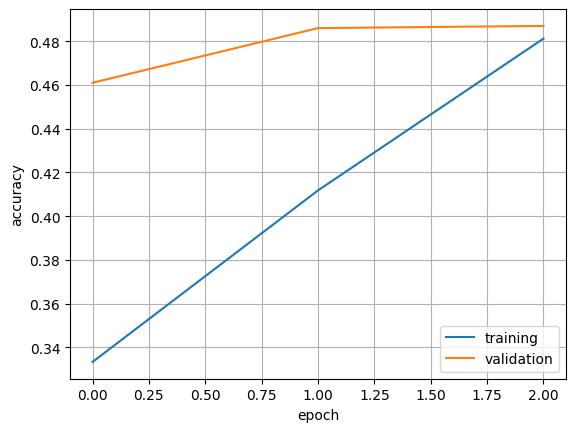

In [22]:
from matplotlib import pyplot as plt
%matplotlib inline
plt.plot(accuracy_track['training'], label='training')
plt.plot(accuracy_track['validation'], label='validation')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.grid()
plt.legend()
plt.show()

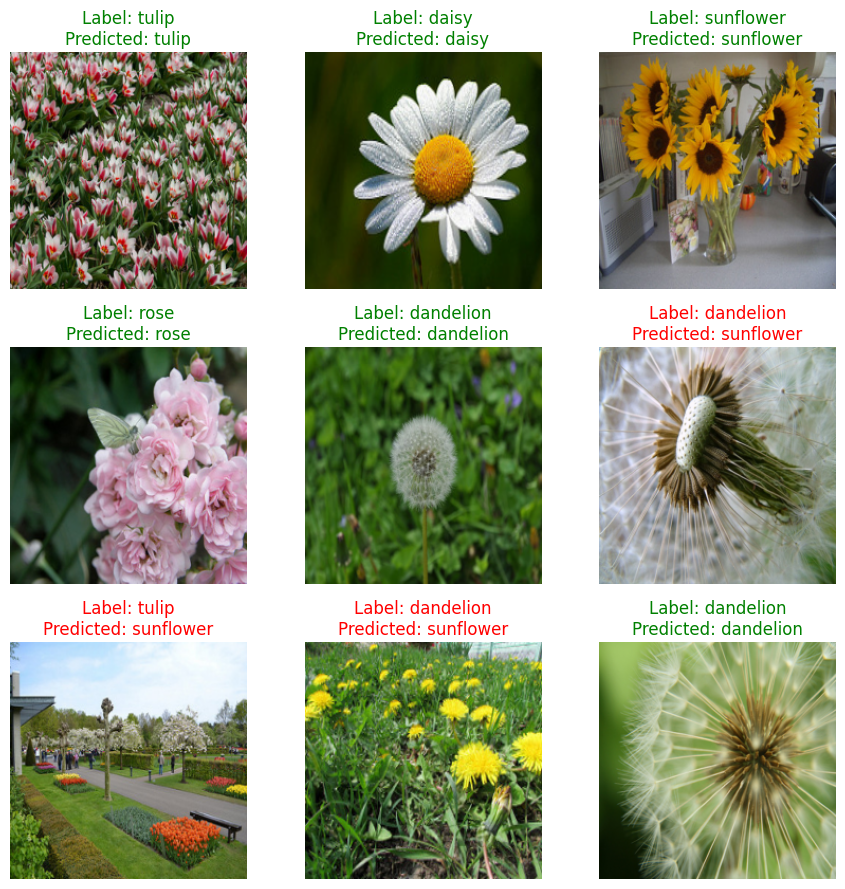

In [23]:
show_predictions(model)

Базовая CNN показала точность около 48.7% за 3 эпохи. Несмотря на огромное количество параметров (207 млн), почти все они находятся в первом полносвязном слое, что приводит к переобучению и медленному обучению. Точность на валидации ниже, чем у других моделей, из-за отсутствия предобученных весов и сложности архитектуры для такого небольшого датасета.

# Практическое задание



В задние представлено логика выполнения с использование tensorflow/keras. Выполнять можно как с использованием tensorflow/keras, так и pytorch.

1. Необходимо обучить предобученную сверточную архитектуру для задач классификации цветов.

В выбранной Вами архитектуре также необходимо **разобраться** с основными её параметрами и принципами работы.

Посмотрите как использовать [модели в PyTorch](https://pytorch.org/vision/stable/models.html) для классификации, выберите одну и используя transfer learning до-обучите модель на классификацию цветов. Чтобы это сделать замените ____ в ячейках ниже на работающий код.

2. Реализовать свою архитектуру, также как в разделе "Сверточная нейросеть с нуля".

3. Сравнить три архитектуры (из раздела "Сверточная нейросеть с нуля", предобученую сверточную архитектуру и свою архитектуру (из п. 2)). Визуализировать полученный результат сравнения.





1. Обучение предобученной сверточной архитектуры для задач классификации цветов

Выбрана модель **ResNet-18**, предобученная на ImageNet (1,2 млн изображений, 1000 классов). В лекции для transfer learning использовался AlexNet; ResNet-18 выбран потому, что у него меньше параметров (11,7 млн против 61 млн у AlexNet) и выше точность на ImageNet, а шаги transfer learning те же.

In [24]:
# ResNet-18 with weights pretrained on ImageNet
model = torchvision.models.resnet18(weights='IMAGENET1K_V1')
model

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [25]:
# Функция для заморозки весов модели
def set_parameter_requires_grad(model):
  for param in model.parameters():
    param.requires_grad = False

set_parameter_requires_grad(model) # freeze all pretrained layers: their weights will not change

In [26]:
# The last layer of ResNet-18 (fc) has 1000 outputs = 1000 ImageNet classes.
# We replace it with a new layer with 5 outputs = 5 kinds of flowers.
# A new layer has requires_grad=True by default, so only this layer will be trained.
model.fc = nn.Linear(model.fc.in_features, 5)
print(model.fc)

Linear(in_features=512, out_features=5, bias=True)


In [27]:
# Проверим все ли сработало правильно, выведем веса, которые будут обучаться
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

print(f'Обучаемых параметров: {count_params(model):,} из {sum(p.numel() for p in model.parameters()):,}')

fc.weight
fc.bias
Обучаемых параметров: 2,565 из 11,179,077


In [28]:
model.to(device) # Отправляем модель на GPU
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001) # only the new layer is optimized
start = time.time()
loss_track, accuracy_track = trainval(model, loaders, optimizer, epochs=5)
results['ResNet-18 (transfer learning)'] = dict(loss=loss_track, acc=accuracy_track, params=count_params(model),
                                                sec_per_epoch=(time.time() - start) / 5)

100%|██████████| 104/104 [00:17<00:00,  5.99it/s]


[training] Epoch: 0.00. Loss: 0.93. Accuracy: 66.67% 


100%|██████████| 32/32 [00:06<00:00,  5.26it/s]


[validation] Epoch: 0.00. Loss: 0.57. Accuracy: 81.30% 


100%|██████████| 104/104 [00:18<00:00,  5.60it/s]


[training] Epoch: 1.00. Loss: 0.52. Accuracy: 83.08% 


... (10 outputs left out)

100%|██████████| 104/104 [00:17<00:00,  5.95it/s]


[training] Epoch: 4.00. Loss: 0.35. Accuracy: 87.68% 


100%|██████████| 32/32 [00:06<00:00,  4.81it/s]

[validation] Epoch: 4.00. Loss: 0.35. Accuracy: 87.90% 


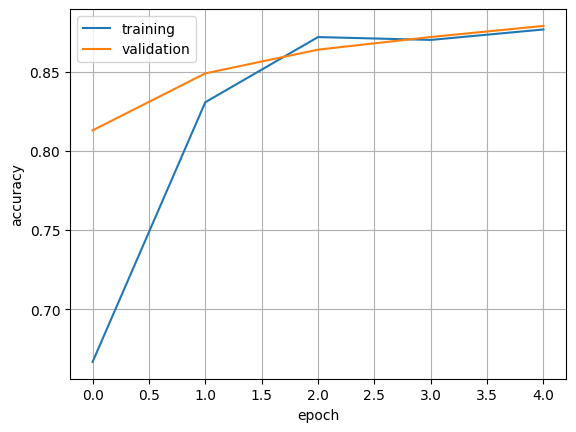

In [29]:
plt.plot(accuracy_track['training'], label='training')
plt.plot(accuracy_track['validation'], label='validation')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.grid()
plt.legend()
plt.show()

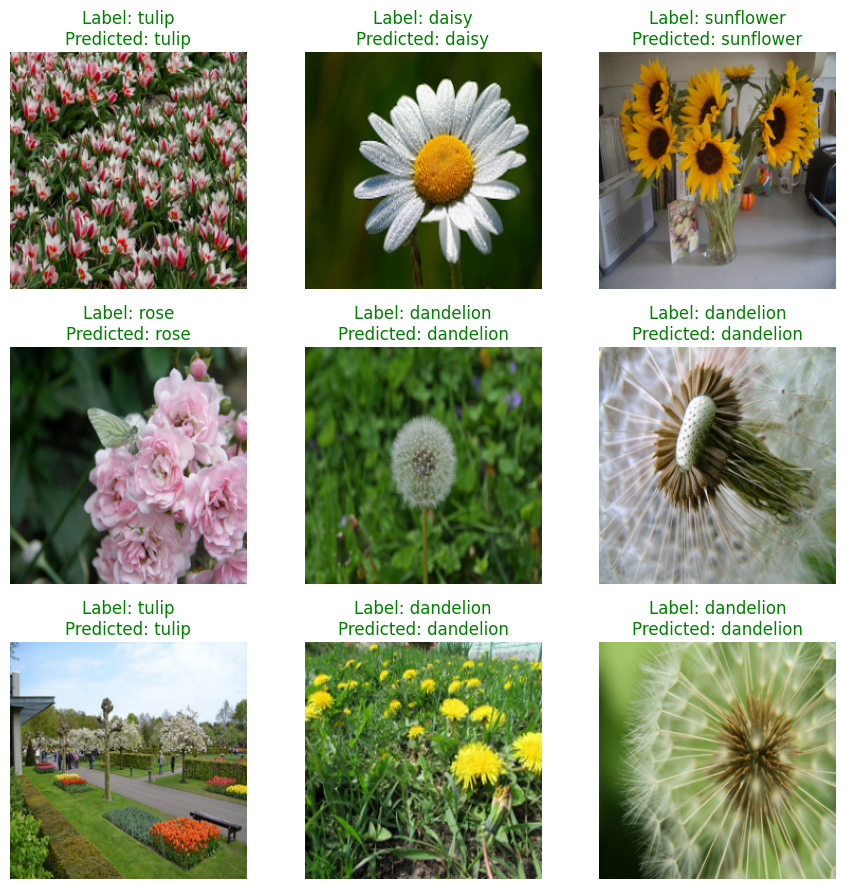

In [30]:
show_predictions(model)

ResNet-18 с Transfer Learning показала наилучший результат (87.9%). Благодаря заморозке весов и замене последнего слоя, модель обучила всего 2,565 параметров. Это позволило достичь высокой точности за 5 эпох. Модель отлично извлекает признаки из изображений благодаря предварительному обучению на ImageNet.

По желанию, можно сохранить веса модели.

In [31]:
weights_fname = os.path.join(DATA_DIR, '..', 'resnet18_flowers.pth')
torch.save(model.state_dict(), weights_fname)

2. Своя архитектура

Своя архитектура — небольшая свёрточная сеть из 5 блоков «свёртка 3 × 3 → ReLU → MaxPool 2 × 2». После каждого блока размер картинки уменьшается в 2 раза (224 → 112 → 56 → 28 → 14 → 7), а число каналов (фильтров) растёт: 16, 32, 64, 128, 128. В конце — два полносвязных слоя.

Идея: базовая сеть очень тяжёлая — почти все её 207 млн параметров находятся в первом полносвязном слое (256·28·28 → 1024). Если уменьшить картинку свёртками и пулингом сильнее (до 7 × 7), полносвязная часть становится маленькой, и сеть обучается быстрее и меньше переобучается.

In [32]:
torch.manual_seed(0)
my_model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1),    # 16 filters 3x3; padding=1 keeps the size 224x224
    nn.ReLU(),
    nn.MaxPool2d(2, 2),                            # 16 x 112 x 112

    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),                            # 32 x 56 x 56

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),                            # 64 x 28 x 28

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),                            # 128 x 14 x 14

    nn.Conv2d(128, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),                            # 128 x 7 x 7

    nn.Flatten(),                                  # 128*7*7 = 6272 numbers
    nn.Linear(128 * 7 * 7, 128),
    nn.ReLU(),
    nn.Linear(128, 5))                             # 5 classes
my_model.to(device)
print(f'Параметров в своей сети: {count_params(my_model):,}')

Параметров в своей сети: 1,048,613


In [33]:
optimizer = torch.optim.Adam(my_model.parameters(), lr=0.001)
start = time.time()
loss_track, accuracy_track = trainval(my_model, loaders, optimizer, epochs=10)
results['Своя CNN'] = dict(loss=loss_track, acc=accuracy_track, params=count_params(my_model),
                           sec_per_epoch=(time.time() - start) / 10)

100%|██████████| 104/104 [00:17<00:00,  6.11it/s]


[training] Epoch: 0.00. Loss: 1.26. Accuracy: 44.88% 


100%|██████████| 32/32 [00:04<00:00,  7.27it/s]


[validation] Epoch: 0.00. Loss: 1.09. Accuracy: 51.50% 


100%|██████████| 104/104 [00:17<00:00,  5.97it/s]


[training] Epoch: 1.00. Loss: 1.03. Accuracy: 58.37% 


... (30 outputs left out)

100%|██████████| 104/104 [00:16<00:00,  6.46it/s]


[training] Epoch: 9.00. Loss: 0.31. Accuracy: 88.67% 


100%|██████████| 32/32 [00:05<00:00,  5.55it/s]

[validation] Epoch: 9.00. Loss: 1.04. Accuracy: 70.10% 


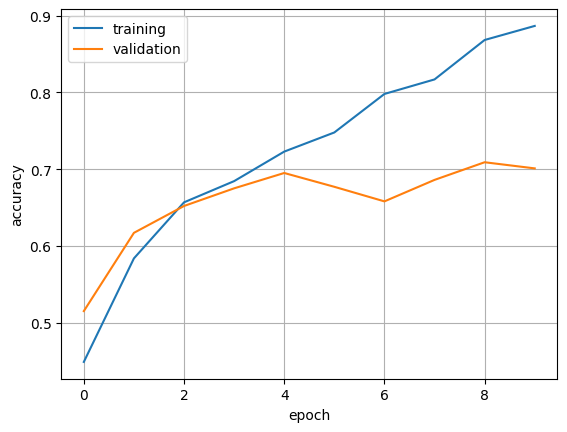

In [34]:
plt.plot(accuracy_track['training'], label='training')
plt.plot(accuracy_track['validation'], label='validation')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.grid()
plt.legend()
plt.show()

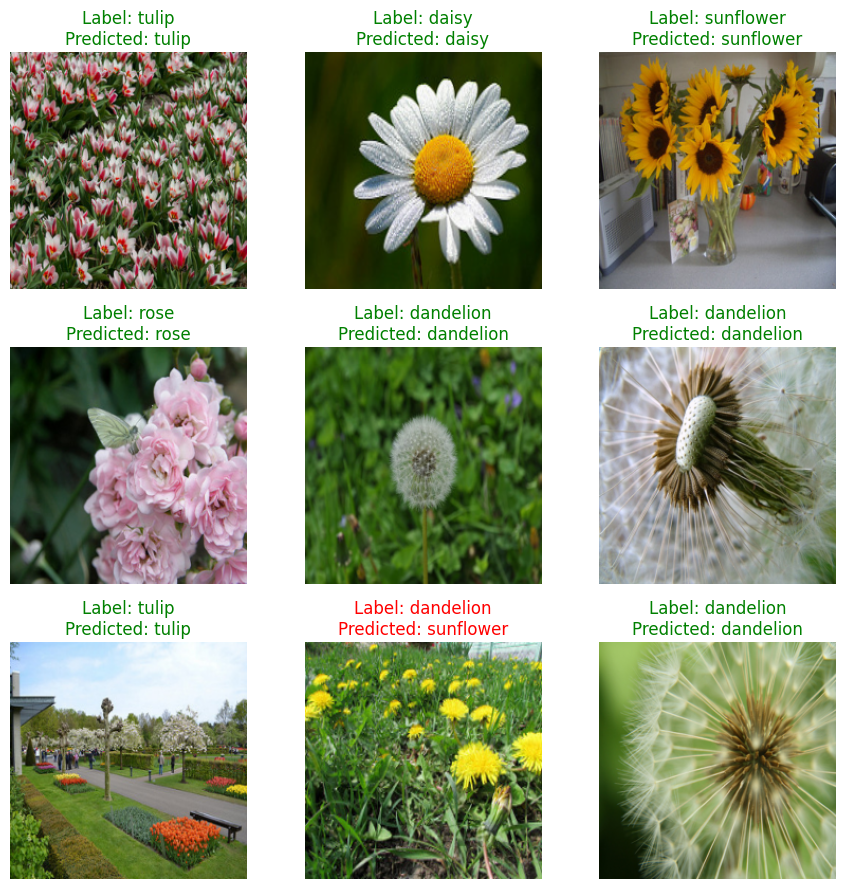

In [35]:
show_predictions(my_model)

Своя CNN архитектура показала точность 70.1% за 10 эпох. Благодаря уменьшению размера изображения с помощью пулинга до 7x7 и уменьшению числа параметров (всего 1 млн), модель обучается быстро и меньше переобучается, чем базовая CNN. Однако точность всё равно ниже, чем у предобученной ResNet-18.

3. Сравнение и вузуализация 3-х архитектур

In [36]:
# Comparison table
table = pd.DataFrame({
    'Модель': list(results.keys()),
    'Обучаемых параметров': [r['params'] for r in results.values()],
    'Эпох': [len(r['acc']['validation']) for r in results.values()],
    'Время эпохи (CPU), мин': [round(r['sec_per_epoch'] / 60, 1) for r in results.values()],
    'Accuracy train, %': [round(100 * r['acc']['training'][-1], 1) for r in results.values()],
    'Accuracy val, %': [round(100 * r['acc']['validation'][-1], 1) for r in results.values()],
})
table

,Модель,Обучаемых параметров,Эпох,"Время эпохи (CPU), мин","Accuracy train, %","Accuracy val, %"
0,Базовая CNN (шаблон),207175365,3,3.1,48.1,48.7
1,ResNet-18 (transfer learning),2565,5,0.4,87.7,87.9
2,Своя CNN,1048613,10,0.4,88.7,70.1


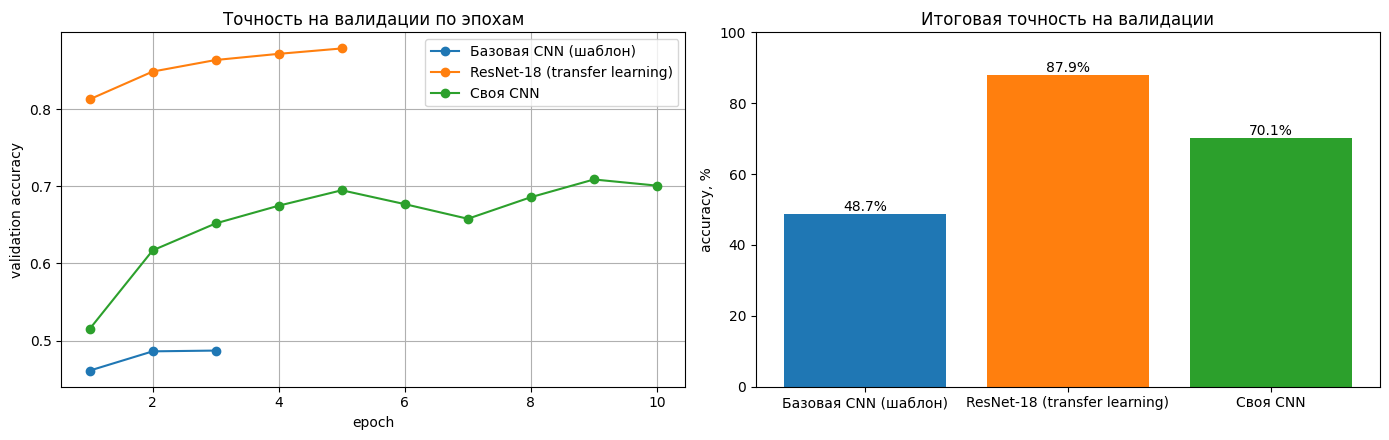

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# left: validation accuracy after every epoch
for name, r in results.items():
    epochs = range(1, len(r['acc']['validation']) + 1)
    axes[0].plot(epochs, r['acc']['validation'], marker='o', label=name)
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('validation accuracy')
axes[0].set_title('Точность на валидации по эпохам')
axes[0].grid()
axes[0].legend()

# right: final validation accuracy
names = list(results.keys())
final_acc = [100 * results[n]['acc']['validation'][-1] for n in names]
bars = axes[1].bar(names, final_acc, color=['tab:blue', 'tab:orange', 'tab:green'])
axes[1].bar_label(bars, fmt='%.1f%%')
axes[1].set_ylabel('accuracy, %')
axes[1].set_ylim(0, 100)
axes[1].set_title('Итоговая точность на валидации')
plt.tight_layout()
plt.show()

Вывод: Предобученная ResNet-18 (Transfer Learning) показала себя лучше всех (87.9%), так как использовала готовые веса. Своя CNN (70.1%) показала хороший результат для обучения с нуля, обогнав базовую архитектуру. Базовая CNN (48.7%) оказалась самой слабой из-за огромного числа параметров и отсутствия предобучения.

## Вопросы.
Добавте описание архитектуры выбранной Вами предобученой сверточной нейронной сети.

Как работает выбранная вами модель сверточной нейронной сети? Какие параметры?

В чем основные отличия между сверточной нейронной сетью и "обычной" полносвязной нейронной сетью?

Что такое transfer learning? Что такое предобучена нейронная сеть?

Что такое функция для заморозки весов модели?

Как работает блок "Сверточная нейросеть с нуля"? Описать сверточный и пулинговый слой.

__ANSWERS__

1. Описание архитектуры ResNet-18: ResNet-18 состоит из 18 слоев и использует остаточные блоки (residual blocks) с "shortcut connections" (пропускными соединениями). Эти соединения решают проблему исчезающего градиента. Архитектура включает начальную свертку 7x7, 4 стадии с basic блоками и финальный полносвязный слой. Параметров около 11.7 млн.

2. Как работает ResNet-18? Модель принимает изображение, пропускает его через сверточные слои, извлекая признаки. "Shortcut connections" прибавляют вход блока к его выходу, что позволяет обучать очень глубокие сети. На выходе получаем вектор вероятностей для 1000 классов (в нашем случае 5).

3. Отличия CNN от полносвязной: В полносвязной сети каждый нейрон соединен со всеми нейронами предыдущего слоя, что дает огромное число параметров. CNN использует свертки (локальные фильтры) и пулинг, что уменьшает число параметров, сохраняет пространственную структуру и учитывает соседство пикселей.

4. Transfer learning и предобученная сеть: Это использование модели, обученной на большом датасете (например, ImageNet), для новой задачи. Предобученная сеть — это сеть, которая уже выучила общие признаки (контуры, текстуры) и может быть дообучена на новом специфическом датасете с меньшими затратами.

5. Заморозка весов: Это установка requires_grad = False для параметров, чтобы они не обновлялись при обучении. Это позволяет сохранить предобученные признаки и обучать только новые слои (например, последний классификатор).

6. Как работает блок "Сверточная нейросеть с нуля":

Сверточный слой (Conv2d): Применяет фильтры (ядра) к изображению, извлекая признаки (края, текстуры). Параметры: размер ядра, число фильтров, шаг (stride), padding.

Пулинговый слой (MaxPool2d): Уменьшает размерность карты признаков, выбирая максимальное значение в окне (например, 2x2). Это снижает вычислительную сложность и делает модель устойчивой к сдвигам.

